# ¡Hola Carolin! ¿Cómo estás? 🙂
<div class="alert alert-block alert-info">
   
Mi nombre es <b>Andrés Barbosa</b> 👋 

Un gusto conocerte, seré tu revisor en este proyecto.
A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y
corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para
mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más
precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que
tengas.
Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como este:
</div>
<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b>
Éxito. Todo se ha hecho de forma correcta.
</div>
<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b>
Observación. Algunas recomendaciones o mejoras menores.
</div>
<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b>
Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado
con comentarios rojos.
</div>
<div class="alert alert-block alert-info">
Puedes responder utilizando este formato:
Respuesta del estudiante.
</div>

Empecemos! 🚀

# Comentario General del Revisor - 1a iteración


<div class="alert alert-block alert-success">
<b>Comentario del revisor - 1a iteración</b> <a class="tocSkip"></a>

Has realizado un análisis integral que conecta adecuadamente la calidad de los datos, la evaluación de rentabilidad, el comportamiento de los usuarios y la comunicación de resultados mediante visualizaciones claras. El proyecto demuestra una buena comprensión de los objetivos de negocio y una correcta aplicación de herramientas analíticas para respaldar la toma de decisiones.

#### Código del Proyecto

- <b>Calidad de datos:</b> Realizaste una validación completa de los datasets, identificando y tratando valores faltantes, registros duplicados, inconsistencias y valores atípicos antes de iniciar el análisis.

- <b>KPIs de negocio:</b> Calculaste correctamente revenue, costos, profit, ticket promedio, volumen de productos y distribución del gasto en marketing, proporcionando una visión clara de la rentabilidad del servicio.

- <b>Funnel de conversión:</b> Construiste las etapas del recorrido del usuario e identificaste de forma adecuada los principales puntos de abandono dentro del proceso de compra.

- <b>Retención por cohortes:</b> Implementaste correctamente el análisis de cohortes para evaluar el comportamiento de los usuarios después del registro y medir su permanencia en el tiempo.

- <b>Experimentación:</b> Desarrollaste un análisis estadístico completo, formulando hipótesis, aplicando una prueba adecuada e interpretando correctamente los resultados obtenidos.


#### Dashboard del Proyecto

- <b>Vista general:</b> La página principal presenta los KPIs clave y permite comprender rápidamente el desempeño general del negocio.
- <b>Vistas de detalle:</b> Las vistas complementarias permiten profundizar en los datos, desglosando los resultados según las dimensiones relevantes del negocio para respaldar el análisis.
- <b>Claridad y estructura:</b> El dashboard está bien organizado, es fácil de leer y comunica los hallazgos de forma efectiva, con una jerarquía visual que guía la lectura de lo general a lo particular.

El proyecto responde satisfactoriamente a las preguntas de negocio planteadas y logra integrar análisis, interpretación y visualización de datos en una solución consistente y bien estructurada.

¡Felicitaciones por el trabajo realizado! Has desarrollado una entrega sólida que transforma los datos en información valiosa para la toma de decisiones y demuestra una adecuada comprensión de los conceptos analíticos aplicados durante el proyecto.

</div>

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from IPython.display import display
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

In [6]:
# Prioriza archivos locales, incluso nombres con (1), (2), etc.; usa la URL oficial como respaldo.
def cargar_csv(nombre):
    carpetas = [Path('.'), Path('upload'), Path('/datasets'), Path('..') / 'upload']
    for carpeta in carpetas:
        exacto = carpeta / (nombre + '.csv')
        candidatos = [exacto] if exacto.exists() else sorted(carpeta.glob(nombre + '(*).csv'))
        if candidatos:
            print('Archivo local:', candidatos[0])
            return pd.read_csv(candidatos[0])
    return pd.read_csv(f'https://practicum-content.s3.amazonaws.com/datasets/{nombre}.csv')
orders = cargar_csv('rappiplus_orders_raw')
catalog = cargar_csv('rappiplus_catalog')
marketing = cargar_csv('rappiplus_marketing_spend')
orders_raw, catalog_raw, marketing_raw = orders.copy(), catalog.copy(), marketing.copy()

Archivo local: rappiplus_orders_raw.csv
,Archivo local: rappiplus_catalog.csv
,Archivo local: rappiplus_marketing_spend.csv


In [7]:
for nombre, df in [('orders', orders), ('catalog', catalog), ('marketing', marketing)]:
    print(nombre, 'filas y columnas:', df.shape)
    display(df.head())
    df.info()

orders filas y columnas: (25100, 12)


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0000,332.6900,0.0000,665.3700
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0000,176.8600,5.0000,171.8600
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0000,102.9900,10.0000,195.9900
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0000,257.8700,15.0000,242.8700
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0000,336.2800,0.0000,336.2800


<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 25100 entries, 0 to 25099
,Data columns (total 12 columns):
, #   Column              Non-Null Count  Dtype  
,---  ------              --------------  -----  
, 0   id_pedido           25100 non-null  object 
, 1   id_usuario          25100 non-null  object 
, 2   fecha_hora_pedido   25100 non-null  object 
, 3   pais                24800 non-null  object 
, 4   dispositivo         25080 non-null  object 
, 5   fuente_referencia   25070 non-null  object 
, 6   nombre_producto     25070 non-null  object 
, 7   categoria_producto  25020 non-null  object 
, 8   cantidad            25050 non-null  float64
, 9   precio_unitario     25050 non-null  float64
, 10  monto_descuento     25050 non-null  float64
, 11  monto_total         25100 non-null  float64
,dtypes: float64(4), object(8)
,memory usage: 2.3+ MB
,catalog filas y columnas: (7, 4)


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.6800,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.1200,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.2100,Bowers LLC
3,Blender-XL-Red,Hogar,176.6400,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.6000,"Rivera, Carr and Finley"


<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 7 entries, 0 to 6
,Data columns (total 4 columns):
, #   Column              Non-Null Count  Dtype  
,---  ------              --------------  -----  
, 0   nombre_producto     7 non-null      object 
, 1   categoria_producto  7 non-null      object 
, 2   costo_unitario      7 non-null      float64
, 3   proveedor           7 non-null      object 
,dtypes: float64(1), object(3)
,memory usage: 352.0+ bytes
,marketing filas y columnas: (1620, 5)


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,"2,446.2500"
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,"2,704.3400"
2,2025-01-01,Mexico,social_Mexico,social,"2,045.0100"
3,2025-01-01,Colombia,organic_Colombia,organic,"2,597.2100"
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,"1,771.4000"


<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 1620 entries, 0 to 1619
,Data columns (total 5 columns):
, #   Column      Non-Null Count  Dtype  
,---  ------      --------------  -----  
, 0   fecha       1620 non-null   object 
, 1   pais        1620 non-null   object 
, 2   id_campaña  1620 non-null   object 
, 3   canal       1519 non-null   object 
, 4   gasto       1620 non-null   float64
,dtypes: float64(1), object(4)
,memory usage: 63.4+ KB


In [8]:
for nombre, df in [('orders', orders), ('catalog', catalog), ('marketing', marketing)]:
    print(nombre, 'duplicados exactos:', df.duplicated().sum())
    display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(),
                          'porcentaje_nulos': df.isna().mean() * 100}))

orders duplicados exactos: 100


,tipo,nulos,porcentaje_nulos
id_pedido,object,0,0.0000
id_usuario,object,0,0.0000
fecha_hora_pedido,object,0,0.0000
pais,object,300,1.1952
dispositivo,object,20,0.0797
fuente_referencia,object,30,0.1195
nombre_producto,object,30,0.1195
categoria_producto,object,80,0.3187
cantidad,float64,50,0.1992
precio_unitario,float64,50,0.1992


catalog duplicados exactos: 0


,tipo,nulos,porcentaje_nulos
nombre_producto,object,0,0.0000
categoria_producto,object,0,0.0000
costo_unitario,float64,0,0.0000
proveedor,object,0,0.0000


marketing duplicados exactos: 0


,tipo,nulos,porcentaje_nulos
fecha,object,0,0.0000
pais,object,0,0.0000
id_campaña,object,0,0.0000
canal,object,101,6.2346
gasto,float64,0,0.0000


In [9]:
display(orders.describe())
for columna in ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']:
    print(columna, orders[columna].unique())
display(catalog)

,cantidad,precio_unitario,monto_descuento,monto_total
count,"25,050.0000","25,050.0000","25,050.0000","25,100.0000"
mean,7.0927,259.3055,4.5008,"2,072.6796"
std,296.2770,138.7265,5.2230,"98,949.9497"
min,-2.0000,20.0300,0.0000,-492.6500
25%,1.0000,138.3775,0.0000,180.5075
50%,2.0000,258.7150,0.0000,341.7500
75%,2.0000,380.3325,10.0000,518.5800
max,"20,000.0000",499.9600,15.0000,"8,840,200.0000"


pais ['Argentina' 'Mexico' 'Colombia' 'mexico' 'colombia' 'argentina' nan]
,dispositivo ['desktop' 'mobile' nan]
,fuente_referencia ['organic' 'paid_search' 'social' nan]
,nombre_producto ['Jacket-Winter-M' 'Tablet-Standard-64GB' 'Blender-XL-Red'
, 'Laptop-Gaming-16GB' 'Sneakers-Urban-42' 'Phone-Pro-128GB'
, 'Vacuum-Pro-Black' nan]
,categoria_producto ['Moda' 'Electronica' 'Hogar' nan]


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.6800,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.1200,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.2100,Bowers LLC
3,Blender-XL-Red,Hogar,176.6400,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.6000,"Rivera, Carr and Finley"
5,Sneakers-Urban-42,Moda,17.2100,Greene-Smith
6,Jacket-Winter-M,Moda,189.3100,Mcmillan-Rhodes


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [10]:
# Duplicados exactos: se conserva una copia. IDs conflictivos se detienen para revisión.
orders = orders.drop_duplicates().copy()
catalog = catalog.drop_duplicates().copy()
marketing = marketing.drop_duplicates().copy()
assert orders.id_pedido.is_unique, 'Hay IDs de pedido conflictivos.'
assert catalog.nombre_producto.is_unique, 'El catálogo no tiene una fila por producto.'
for df in [orders, catalog, marketing]:
    for c in df.select_dtypes(include='object'):
        df[c] = df[c].astype('string').str.strip().replace('', pd.NA)
for df in [orders, marketing]:
    df['pais'] = df.pais.str.lower().map({'mexico':'Mexico','méxico':'Mexico',
                                        'colombia':'Colombia','argentina':'Argentina'}).fillna('No informado')
orders['fecha_pedido'] = pd.to_datetime(orders.fecha_hora_pedido, errors='coerce')
marketing['fecha'] = pd.to_datetime(marketing.fecha, errors='coerce')
for c in ['cantidad','precio_unitario','monto_descuento','monto_total']:
    orders[c] = pd.to_numeric(orders[c], errors='coerce')
catalog['costo_unitario'] = pd.to_numeric(catalog.costo_unitario, errors='coerce')
marketing['gasto'] = pd.to_numeric(marketing.gasto, errors='coerce')
# Categoría recuperable mediante la fuente maestra; el producto ausente no se inventa.
# Crear la correspondencia producto → categoría usando el tipo object.
categorias = (
    catalog
    .set_index('nombre_producto')['categoria_producto']
    .astype('object')
    .to_dict()
)

# Recuperar la categoría desde el catálogo.
orders['categoria_producto'] = (
    orders['nombre_producto']
    .astype('object')
    .map(categorias)
)

# Verificar el resultado.
display(orders[['nombre_producto', 'categoria_producto']].head())
for c in ['dispositivo','fuente_referencia']:
    orders[c] = orders[c].str.lower().fillna('No informado')
# El ID de campaña contiene el canal; se recupera sólo si coincide con los canales conocidos.
canal_recuperado = marketing['id_campaña'].str.replace(r'_(Mexico|Colombia|Argentina)$', '', regex=True)
marketing['canal'] = marketing.canal.fillna(canal_recuperado.where(canal_recuperado.isin(['organic','paid_search','social'])))
assert catalog.costo_unitario.notna().all() and catalog.costo_unitario.ge(0).all()
assert marketing[['fecha','canal','gasto']].notna().all().all() and marketing.gasto.ge(0).all()
assert not marketing.duplicated(['fecha','pais','id_campaña']).any()

,nombre_producto,categoria_producto
0,Jacket-Winter-M,Moda
1,Tablet-Standard-64GB,Electrónica
2,Blender-XL-Red,Hogar
3,Tablet-Standard-64GB,Electrónica
4,Blender-XL-Red,Hogar


In [11]:
# No se imputan cantidades, precios o descuentos con promedios: alteraría ingresos y costos.
# Pedidos extraordinarios se ponen en cuarentena usando una regla exploratoria IQR.
q1, q3 = orders.cantidad.quantile([.25, .75])
limite_cantidad = q3 + 1.5 * (q3 - q1)
reglas = pd.DataFrame({
    'fecha_invalida': orders.fecha_pedido.isna(),
    'producto_desconocido': ~orders.nombre_producto.isin(catalog.nombre_producto),
    'numerico_faltante': orders[['cantidad','precio_unitario','monto_descuento','monto_total']].isna().any(axis=1),
    'cantidad_invalida': orders.cantidad.le(0) | (orders.cantidad.mod(1).ne(0) & orders.cantidad.notna()),
    'cantidad_atipica': orders.cantidad.gt(limite_cantidad),
    'precio_invalido': orders.precio_unitario.le(0),
    'descuento_invalido': orders.monto_descuento.lt(0) | orders.monto_descuento.gt(orders.cantidad * orders.precio_unitario),
    'total_negativo': orders.monto_total.lt(0),
    # Tolerancia de dos centavos: precio y total pudieron redondearse independientemente.
    'monto_inconsistente': (orders.monto_total - (orders.cantidad * orders.precio_unitario - orders.monto_descuento)).abs().gt(.02)
})
excluir = reglas.any(axis=1)
orders_revision = orders.loc[excluir].copy()
orders_revision['motivo_revision'] = reglas.loc[excluir].apply(lambda r: ', '.join(r.index[r]), axis=1)
display(reglas.sum().rename('filas_por_motivo').to_frame())
print('Filas únicas en cuarentena:', excluir.sum(), 'Umbral IQR:', limite_cantidad)
orders = orders.loc[~excluir].copy()
orders['cantidad'] = orders.cantidad.astype('int64')
orders['fecha_hora_pedido'] = orders.fecha_pedido
print('Pedidos utilizables:', len(orders))

,filas_por_motivo
fecha_invalida,0
producto_desconocido,30
numerico_faltante,50
cantidad_invalida,4
cantidad_atipica,10
precio_invalido,0
descuento_invalido,4
total_negativo,4
monto_inconsistente,3


Filas únicas en cuarentena: 94 Umbral IQR: 3.5
,Pedidos utilizables: 24906


In [12]:
assert orders.id_pedido.is_unique
assert orders[['fecha_pedido','nombre_producto','cantidad','precio_unitario','monto_descuento','monto_total']].notna().all().all()
assert orders.cantidad.gt(0).all() and orders.monto_total.ge(0).all()
assert (orders.monto_total - (orders.cantidad * orders.precio_unitario - orders.monto_descuento)).abs().le(.02).all()
qa = pd.DataFrame({'dataset':['orders','catalog','marketing'],
                   'filas_originales':[len(orders_raw),len(catalog_raw),len(marketing_raw)],
                   'filas_limpias':[len(orders),len(catalog),len(marketing)]})
display(qa)
print('Las filas por motivo pueden solaparse. País No informado se conserva para no perder ventas válidas.')

,dataset,filas_originales,filas_limpias
0,orders,25100,24906
1,catalog,7,7
2,marketing,1620,1620


Las filas por motivo pueden solaparse. País No informado se conserva para no perder ventas válidas.


---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [13]:
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)
orders_revision.to_csv('orders_revision.csv', index=False)
print('Exportados tres CSV limpios y archivo auxiliar de auditoría.')

Exportados tres CSV limpios y archivo auxiliar de auditoría.


---

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - Excelente La exploración inicial de los datasets, es detallada y permite identificar desde el comienzo aspectos importantes de la calidad de los datos.
</div>

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [14]:
ventas = orders.merge(catalog[['nombre_producto','costo_unitario']], on='nombre_producto',
                      how='left', validate='many_to_one')
assert len(ventas) == len(orders) and ventas.costo_unitario.notna().all()
ventas['revenue'] = ventas.monto_total
ventas['cost'] = ventas.cantidad * ventas.costo_unitario
ventas['profit_bruto'] = ventas.revenue - ventas.cost
inicio, fin = ventas.fecha_pedido.min(), ventas.fecha_pedido.max()
marketing_periodo = marketing.loc[marketing.fecha.between(inicio, fin)].copy()
revenue, costo, gasto = ventas.revenue.sum(), ventas.cost.sum(), marketing_periodo.gasto.sum()
profit = revenue - costo - gasto
kpis = pd.Series({'Pedidos':ventas.id_pedido.nunique(), 'Revenue total':revenue,
    'Costo productos':costo, 'Profit bruto':revenue-costo, 'Gasto marketing':gasto,
    'Profit después de marketing':profit, 'Margen después de marketing (%)':100*profit/revenue,
    'Ticket promedio':revenue/ventas.id_pedido.nunique(),
    'Productos promedio por orden':ventas.cantidad.sum()/ventas.id_pedido.nunique()})
display(kpis.to_frame('valor'))
print('Periodo:', inicio.date(), 'a', fin.date())
print('Las unidades monetarias no están especificadas. Se supone una unidad común; confirmar antes de decisiones.')

,valor
Pedidos,"24,906.0000"
Revenue total,"9,610,018.9400"
Costo productos,"3,828,869.0100"
Profit bruto,"5,781,149.9300"
Gasto marketing,"2,871,843.5300"
Profit después de marketing,"2,909,306.4000"
Margen después de marketing (%),30.2737
Ticket promedio,385.8516
Productos promedio por orden,1.5049


Periodo: 2025-01-01 a 2025-06-30
,Las unidades monetarias no están especificadas. Se supone una unidad común; confirmar antes de decisiones.


In [15]:
por_producto = ventas.groupby(['nombre_producto','categoria_producto']).agg(
    pedidos=('id_pedido','nunique'), cantidad_vendida=('cantidad','sum'),
    revenue=('revenue','sum'), cost=('cost','sum'), profit_bruto=('profit_bruto','sum')).sort_values('cantidad_vendida',ascending=False)
por_producto['margen_bruto_pct'] = 100*por_producto.profit_bruto/por_producto.revenue
display(por_producto)
print('Producto más vendido por unidades:', por_producto.index[0][0])
por_canal = marketing_periodo.groupby('canal').gasto.sum().sort_values(ascending=False)
display(por_canal.to_frame('gasto_marketing'))
# No se atribuye marketing a productos: no hay una regla de atribución suministrada.

,,pedidos,cantidad_vendida,revenue,cost,profit_bruto,margen_bruto_pct
nombre_producto,categoria_producto,,,,,,
Vacuum-Pro-Black,Hogar,4170,6284,"1,621,051.8500","104,314.4000","1,516,737.4500",93.5650
Blender-XL-Red,Hogar,4176,6279,"1,611,574.5900","1,109,122.5600","502,452.0300",31.1777
Jacket-Winter-M,Moda,4166,6256,"1,606,586.1700","1,184,323.3600","422,262.8100",26.2832
Sneakers-Urban-42,Moda,4129,6172,"1,566,075.9300","106,220.1200","1,459,855.8100",93.2174
Laptop-Gaming-16GB,Electrónica,2768,4198,"1,084,672.9800","1,178,294.6400","-93,621.6600",-8.6313
Tablet-Standard-64GB,Electrónica,2764,4153,"1,062,922.8000","104,697.1300","958,225.6700",90.1501
Phone-Pro-128GB,Electrónica,2733,4140,"1,057,134.6200","41,896.8000","1,015,237.8200",96.0368


Producto más vendido por unidades: Vacuum-Pro-Black


,gasto_marketing
canal,
social,"976,818.3700"
organic,"972,650.9600"
paid_search,"922,374.2000"


,revenue,cost,profit_bruto,marketing,profit
fecha_pedido,,,,,
2025-01,"1,654,676.9000","661,410.4300","993,266.4700","500,186.6000","493,079.8700"
2025-02,"1,439,010.5000","582,461.2100","856,549.2900","448,321.6400","408,227.6500"
2025-03,"1,657,796.3200","658,068.9200","999,727.4000","516,014.4600","483,712.9400"
2025-04,"1,595,409.0200","645,912.6400","949,496.3800","445,179.8200","504,316.5600"
2025-05,"1,648,037.2600","640,244.6500","1,007,792.6100","499,181.3400","508,611.2700"
2025-06,"1,615,088.9400","640,771.1600","974,317.7800","462,959.6700","511,358.1100"


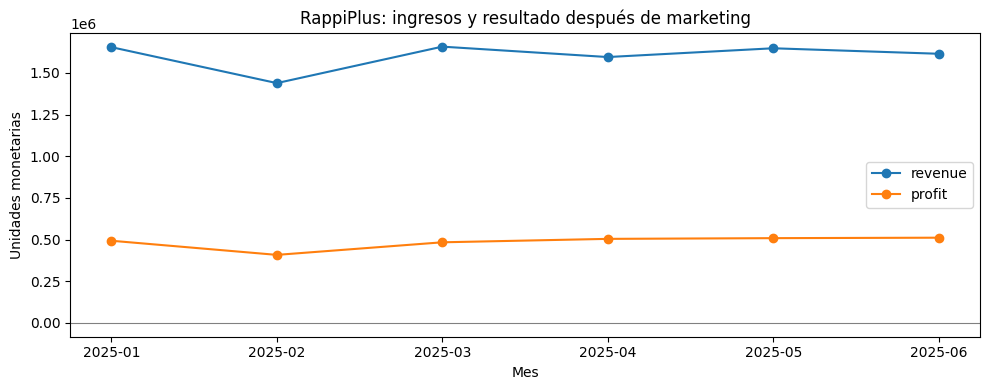

Sensibilidad si se validaran pedidos de cantidad atípica:
,Revenue adicional: 42344700.0 Profit bruto adicional: 3049500.0


In [16]:
mensual = ventas.groupby(ventas.fecha_pedido.dt.to_period('M')).agg(
    revenue=('revenue','sum'), cost=('cost','sum'), profit_bruto=('profit_bruto','sum'))
mensual['marketing'] = marketing_periodo.groupby(marketing_periodo.fecha.dt.to_period('M')).gasto.sum().reindex(mensual.index,fill_value=0)
mensual['profit'] = mensual.profit_bruto - mensual.marketing
display(mensual)
fig, ax = plt.subplots(figsize=(10,4))
mensual[['revenue','profit']].set_axis(mensual.index.astype(str)).plot(ax=ax,marker='o')
ax.set(title='RappiPlus: ingresos y resultado después de marketing',xlabel='Mes',ylabel='Unidades monetarias')
ax.axhline(0,color='grey',linewidth=.8);plt.tight_layout();plt.show()
# Sensibilidad: no confundir cuarentena con eliminación confirmada de errores.
sens = orders_revision.loc[orders_revision.cantidad.gt(limite_cantidad) & orders_revision.nombre_producto.isin(catalog.nombre_producto)].copy()
sens['costo'] = sens.cantidad * sens.nombre_producto.map(catalog.set_index('nombre_producto').costo_unitario)
print('Sensibilidad si se validaran pedidos de cantidad atípica:')
print('Revenue adicional:', sens.monto_total.sum(), 'Profit bruto adicional:', (sens.monto_total-sens.costo).sum())

---

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - Los KPIs de rentabilidad y comportamiento de ventas fueron calculados e interpretados correctamente, proporcionando una visión clara del desempeño financiero del negocio y de los productos que más contribuyen a las ventas.
</div>

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd

# Ejecutar las consultas SQL requiere acceso autorizado a la base de TripleTen.
# Esta versión del portafolio conserva las consultas y los resultados guardados.
engine = None
SQL_DISPONIBLE = False


In [5]:
query_events = '''SELECT * FROM events LIMIT 10;'''
events = ejecutar_sql(query_events)
display(events)

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica
5,user_4402,0892643c-f80d-4eb4-9ca8-3638b16c6ed4,begin_checkout,2025-04-21,Argentina,desktop,paid_search,Hogar
6,user_767,0005a13c-3c1f-496b-a26a-f3c282f19e13,begin_checkout,2025-03-01,Mexico,mobile,social,Electronica
7,user_2694,b07336e6-1207-4ee1-82e3-1fa7fbd194e3,add_payment_info,2025-03-22,Colombia,desktop,organic,Hogar
8,user_7209,f42bd8cd-aff2-4b7e-94e2-d4d885d23afc,add_to_cart,2025-05-07,Mexico,desktop,organic,Moda
9,user_1788,abf1af77-e96b-4490-9efb-3fa5d8271ad4,add_to_cart,2025-05-13,Argentina,desktop,organic,Moda


In [6]:
query_eventos_disponibles = '''
SELECT nombre_evento, COUNT(*) AS eventos, COUNT(DISTINCT id_usuario) AS usuarios
FROM events GROUP BY nombre_evento ORDER BY usuarios DESC;
'''
display(ejecutar_sql(query_eventos_disponibles))
# Comprueba que los nombres encontrados coinciden con el orden siguiente.

,nombre_evento,eventos,usuarios
0,first_visit,29957,7796
1,add_to_cart,24157,7634
2,select_item,23887,7582
3,begin_checkout,17971,7208
4,add_payment_info,12018,6250
5,purchase,12010,6240


In [10]:
# Funnel de alcance: usuarios únicos por evento, no secuencia temporal obligatoria.
query_totals = '''
WITH etapas(nombre_evento, orden) AS (
    VALUES
        ('first_visit', 1),
        ('select_item', 2),
        ('add_to_cart', 3),
        ('begin_checkout', 4),
        ('add_payment_info', 5),
        ('purchase', 6)
)
SELECT e.orden, e.nombre_evento, COUNT(DISTINCT v.id_usuario) AS usuarios
FROM etapas e LEFT JOIN events v ON e.nombre_evento = v.nombre_evento
GROUP BY e.orden, e.nombre_evento ORDER BY e.orden;
'''
totals = ejecutar_sql(query_totals)
display(totals)

,orden,nombre_evento,usuarios
0,1,first_visit,7796
1,2,select_item,7582
2,3,add_to_cart,7634
3,4,begin_checkout,7208
4,5,add_payment_info,6250
5,6,purchase,6240


In [8]:

query_conversion = '''
WITH etapas(nombre_evento, orden) AS (
    VALUES
        ('first_visit', 1),
        ('select_item', 2),
        ('add_to_cart', 3),
        ('begin_checkout', 4),
        ('add_payment_info', 5),
        ('purchase', 6)
),
totales AS (
 SELECT e.orden, e.nombre_evento, COUNT(DISTINCT v.id_usuario) AS usuarios
 FROM etapas e LEFT JOIN events v ON v.nombre_evento = e.nombre_evento
 GROUP BY e.orden, e.nombre_evento
), pasos AS (
 SELECT *, LAG(usuarios) OVER (ORDER BY orden) AS usuarios_anterior,
 FIRST_VALUE(usuarios) OVER (ORDER BY orden) AS usuarios_inicio FROM totales
)
SELECT *, usuarios_anterior-usuarios AS usuarios_perdidos,
 ROUND(100.0*usuarios/NULLIF(usuarios_anterior,0),2) AS conversion_paso_pct,
 ROUND(100.0*(usuarios_anterior-usuarios)/NULLIF(usuarios_anterior,0),2) AS abandono_pct,
 ROUND(100.0*usuarios/NULLIF(usuarios_inicio,0),2) AS conversion_acumulada_pct
FROM pasos ORDER BY orden;
'''
conversion = ejecutar_sql(query_conversion)
display(conversion)
if not conversion.empty:
    print('Mayor pérdida absoluta:', conversion.loc[conversion.usuarios_perdidos.idxmax(),'nombre_evento'])
    print('Mayor abandono relativo:', conversion.loc[conversion.abandono_pct.idxmax(),'nombre_evento'])
    print('Conversión final (%):', conversion.iloc[-1].conversion_acumulada_pct)
    if (conversion.usuarios_perdidos.dropna()<0).any():
        print('Hay aumentos entre etapas: este funnel de alcance no demuestra una secuencia de compra.')


,orden,nombre_evento,usuarios,usuarios_anterior,usuarios_inicio,usuarios_perdidos,conversion_paso_pct,abandono_pct,conversion_acumulada_pct
0,1,first_visit,7796,NaN,7796,NaN,NaN,NaN,100.00
1,2,select_item,7582,7796.0,7796,214.0,97.26,2.74,97.26
2,3,add_to_cart,7634,7582.0,7796,-52.0,100.69,-0.69,97.92
3,4,begin_checkout,7208,7634.0,7796,426.0,94.42,5.58,92.46
4,5,add_payment_info,6250,7208.0,7796,958.0,86.71,13.29,80.17
5,6,purchase,6240,6250.0,7796,10.0,99.84,0.16,80.04


Mayor pérdida absoluta: add_payment_info
,Mayor abandono relativo: add_payment_info
,Conversión final (%): 80.04
,Hay aumentos entre etapas: este funnel de alcance no demuestra una secuencia de compra.


---

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - El análisis del funnel está bien fundamentado y complementa los resultados numéricos con una interpretación de negocio clara, permitiendo identificar la etapa con mayor pérdida de usuarios y evaluar el desempeño general del proceso de conversión. 
</div>

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [22]:
query_users = '''SELECT * FROM users LIMIT 10;'''
users = ejecutar_sql(query_users)
display(users)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free
3,user_3,2025-03-04,Mexico,desktop,free
4,user_4,2025-02-27,Argentina,desktop,free
5,user_5,2025-02-05,Colombia,desktop,free
6,user_6,2025-01-27,Mexico,mobile,free
7,user_7,2025-05-20,Colombia,mobile,free
8,user_8,2025-01-23,Mexico,mobile,free
9,user_9,2025-04-19,Colombia,desktop,free


In [23]:
query_user_activity = '''SELECT * FROM user_activity LIMIT 10;'''
user_activity = ejecutar_sql(query_user_activity)
display(user_activity)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1
3,user_0,2025-02-26,28,0
4,user_1,2025-01-14,7,0
5,user_1,2025-01-21,14,0
6,user_1,2025-01-28,21,1
7,user_1,2025-02-04,28,0
8,user_2,2025-03-19,7,0
9,user_2,2025-03-26,14,1


,cohorte,clientes_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01-01,1627,697,668,656,42.8400,41.0600,40.3200
1,2025-02-01,1444,611,609,635,42.3100,42.1700,43.9800
2,2025-03-01,1636,677,705,690,41.3800,43.0900,42.1800
3,2025-04-01,1606,680,697,663,42.3400,43.4000,41.2800
4,2025-05-01,1687,695,676,706,41.2000,40.0700,41.8500


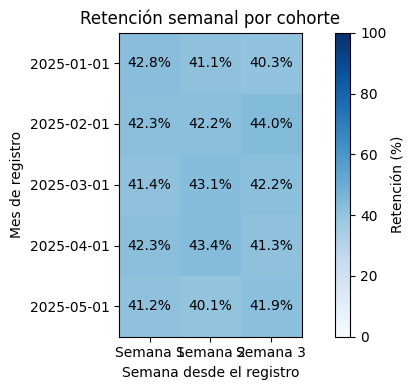

Cohorte con mayor retención en semana 3:


cohorte     2025-02-01
semana_3       43.9800
Name: 1, dtype: object

In [29]:
# Semana 1 = días 7–13; semana 2 = 14–20; semana 3 = 21–27 desde registro.
# Se usan fechas reales y activo=1, contando cada usuario sólo una vez por semana.
# Cohortes inmaduras muestran NULL, no falsa retención cero.
query_cohort_retention_final = '''
WITH limite AS (SELECT MAX(CAST(fecha_actividad AS DATE)) AS fecha_corte FROM user_activity),
base AS (
 SELECT id_usuario, MIN(CAST(fecha_registro AS DATE)) AS fecha_registro
 FROM users GROUP BY id_usuario
), flags AS (
 SELECT u.id_usuario, u.fecha_registro,
 DATE_TRUNC('month', u.fecha_registro)::DATE AS cohorte,
 MAX(CASE WHEN a.activo=1 AND CAST(a.fecha_actividad AS DATE)-u.fecha_registro BETWEEN 7 AND 13 THEN 1 ELSE 0 END) AS w1,
 MAX(CASE WHEN a.activo=1 AND CAST(a.fecha_actividad AS DATE)-u.fecha_registro BETWEEN 14 AND 20 THEN 1 ELSE 0 END) AS w2,
 MAX(CASE WHEN a.activo=1 AND CAST(a.fecha_actividad AS DATE)-u.fecha_registro BETWEEN 21 AND 27 THEN 1 ELSE 0 END) AS w3
 FROM base u LEFT JOIN user_activity a ON a.id_usuario=u.id_usuario
 GROUP BY u.id_usuario,u.fecha_registro
), agregado AS (
 SELECT cohorte, COUNT(*) AS clientes_iniciales, MAX(fecha_registro) AS ultimo_registro,
 SUM(w1) AS w1, SUM(w2) AS w2, SUM(w3) AS w3
 FROM flags GROUP BY cohorte
)
SELECT cohorte, clientes_iniciales,
 CASE WHEN ultimo_registro+13<=fecha_corte THEN w1 END AS retenido_w1,
 CASE WHEN ultimo_registro+20<=fecha_corte THEN w2 END AS retenido_w2,
 CASE WHEN ultimo_registro+27<=fecha_corte THEN w3 END AS retenido_w3,
 CASE WHEN ultimo_registro+13<=fecha_corte THEN ROUND(100.0*w1/NULLIF(clientes_iniciales,0),2) END AS semana_1,
 CASE WHEN ultimo_registro+20<=fecha_corte THEN ROUND(100.0*w2/NULLIF(clientes_iniciales,0),2) END AS semana_2,
 CASE WHEN ultimo_registro+27<=fecha_corte THEN ROUND(100.0*w3/NULLIF(clientes_iniciales,0),2) END AS semana_3
FROM agregado CROSS JOIN limite ORDER BY cohorte;
'''

# Ejecutar la consulta y mostrar los resultados
cohorte_final = ejecutar_sql(query_cohort_retention_final)
display(cohorte_final)

# Dibujar el gráfico dentro de una función
def graficar_retencion(datos):
    if datos.empty:
        print('No hay datos disponibles. Revisa la conexión SQL.')
        return

    matriz = (
        datos
        .set_index('cohorte')[['semana_1', 'semana_2', 'semana_3']]
        .astype(float)
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    imagen = ax.imshow(
        matriz.values,
        vmin=0,
        vmax=100,
        cmap='Blues'
    )

    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(['Semana 1', 'Semana 2', 'Semana 3'])

    ax.set_yticks(list(range(len(matriz))))
    ax.set_yticklabels(matriz.index.astype(str).tolist())

    for fila in range(len(matriz)):
        for columna in range(3):
            valor = matriz.iloc[fila, columna]
            texto = 'Pendiente' if pd.isna(valor) else f'{valor:.1f}%'
            ax.text(
                columna,
                fila,
                texto,
                ha='center',
                va='center'
            )

    ax.set_title('Retención semanal por cohorte')
    ax.set_xlabel('Semana desde el registro')
    ax.set_ylabel('Mes de registro')
    fig.colorbar(imagen, ax=ax, label='Retención (%)')
    plt.tight_layout()
    plt.show()

    validas = datos.dropna(subset=['semana_3'])
    if not validas.empty:
        print('Cohorte con mayor retención en semana 3:')
        display(
            validas.loc[
                validas['semana_3'].idxmax(),
                ['cohorte', 'semana_3']
            ]
        )

graficar_retencion(cohorte_final)




---

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - El análisis de cohortes está correctamente estructurado y permite evaluar la retención de usuarios a lo largo del tiempo, mostrando de forma clara el comportamiento de las distintas cohortes y la estabilidad de las tasas de permanencia entre semanas.
</div>

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

**H₀:** la probabilidad de compra es igual en control y tratamiento (pT = pC).
**H₁:** las probabilidades difieren (pT ≠ pC).
**Test:** z bilateral de dos proporciones independientes; α = 0,05.
La columna real de conversión se llama `convirtio`. No se prueba la duración de sesión como métrica principal.
La diferencia e intervalo se reportan en puntos porcentuales; el lift es relativo.

In [30]:
experiment = cargar_csv('experiment_checkout_ui').drop_duplicates().copy()
experiment['timestamp'] = pd.to_datetime(experiment.timestamp, errors='coerce')
assert experiment.id_usuario.is_unique, 'Revisar usuarios repetidos o asignados a ambas variantes.'
assert set(experiment.variante.unique()) == {'control','tratamiento'}
assert experiment.convirtio.isin([0,1]).all()
assert experiment[['id_usuario','variante','convirtio','timestamp']].notna().all().all()
resumen_ab = experiment.groupby('variante').convirtio.agg(['count','sum','mean'])
resumen_ab.columns=['usuarios','compras','conversion']
display(resumen_ab)
print('Periodo A/B:',experiment.timestamp.min().date(),experiment.timestamp.max().date())
# SRM: se supone asignación prevista 50/50; confirmar diseño con el responsable.
srm = stats.chisquare(resumen_ab.usuarios.to_numpy())
print('SRM p-value (supuesto 50/50):',srm.pvalue)
display(pd.crosstab([experiment.pais, experiment.dispositivo],experiment.variante))

Archivo local: experiment_checkout_ui.csv


,usuarios,compras,conversion
variante,,,
control,4965,779,0.1569
tratamiento,5035,820,0.1629


Periodo A/B: 2025-01-01 2025-06-30
,SRM p-value (supuesto 50/50): 0.48392730444614596


variante               control  tratamiento
pais      dispositivo                      
Argentina desktop          805          847
          mobile           851          814
Colombia  desktop          845          807
          mobile           787          839
Mexico    desktop          858          880
          mobile           819          848

In [26]:
nc, nt = resumen_ab.loc['control','usuarios'], resumen_ab.loc['tratamiento','usuarios']
xc, xt = resumen_ab.loc['control','compras'], resumen_ab.loc['tratamiento','compras']
pc, pt = xc/nc, xt/nt
assert min(xc,nc-xc,xt,nt-xt)>=10, 'Preferir Fisher con conteos pequeños.'
p_pool=(xc+xt)/(nc+nt)
se_pool=np.sqrt(p_pool*(1-p_pool)*(1/nc+1/nt))
z=(pt-pc)/se_pool
p_value=2*stats.norm.sf(abs(z))
diferencia=pt-pc
se=np.sqrt(pc*(1-pc)/nc+pt*(1-pt)/nt)
ic=(diferencia-stats.norm.ppf(.975)*se, diferencia+stats.norm.ppf(.975)*se)
alpha=.05
print(f'z={z:.4f}; p-value={p_value:.6g}; alfa={alpha}')
print(f'Control={pc:.2%}; tratamiento={pt:.2%}')
print(f'Diferencia={100*diferencia:.3f} puntos porcentuales; lift relativo={diferencia/pc:.2%}')
print(f'IC95% diferencia: [{100*ic[0]:.3f}, {100*ic[1]:.3f}] puntos porcentuales')

z=0.8133; p-value=0.416059; alfa=0.05
,Control=15.69%; tratamiento=16.29%
,Diferencia=0.596 puntos porcentuales; lift relativo=3.80%
,IC95% diferencia: [-0.840, 2.033] puntos porcentuales


No se rechaza H₀: no hay evidencia suficiente de diferencia; esto no demuestra igualdad.
,Recomendación: no desplegar por una supuesta mejora; revisar diseño y potencia.
,El test asume aleatorización, independencia y ausencia de revisión anticipada. No demuestra mayor rentabilidad ni efecto de la suscripción.


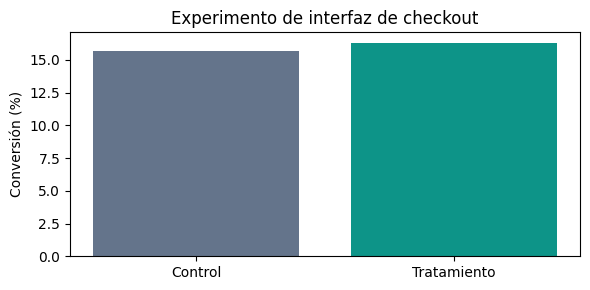

In [31]:
if p_value < alpha:
    print('Se rechaza H₀: hay evidencia de una diferencia de conversión.')
    print('Tratamiento mejora la conversión.' if diferencia>0 else 'Tratamiento reduce la conversión.')
else:
    print('No se rechaza H₀: no hay evidencia suficiente de diferencia; esto no demuestra igualdad.')
print('Recomendación:', 'evaluar despliegue gradual con métricas de margen, errores y abandono.'
      if p_value<alpha and diferencia>0 else 'no desplegar por una supuesta mejora; revisar diseño y potencia.')
print('El test asume aleatorización, independencia y ausencia de revisión anticipada. No demuestra mayor rentabilidad ni efecto de la suscripción.')
fig, ax=plt.subplots(figsize=(6,3));ax.bar(['Control','Tratamiento'],[100*pc,100*pt],color=['#64748b','#0d9488'])
ax.set(ylabel='Conversión (%)',title='Experimento de interfaz de checkout');plt.tight_layout();plt.show()

---

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - El análisis experimental está correctamente desarrollado, desde la formulación de hipótesis hasta la interpretación de los resultados. La prueba estadística aplicada permite concluir de forma fundamentada que no existe evidencia suficiente para afirmar que la modificación evaluada genere cambios significativos en la tasa de conversión.
</div>

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

### Interpretación y recomendaciones finales



1. Calidad de los datos
   
La fuente original contenía 25.100 registros de pedidos. Después de eliminar 100 duplicados exactos y separar 94 pedidos para revisión, quedaron 24.906 pedidos utilizables, equivalentes al 99,23 % de las filas originales.
Se corrigieron diferencias en los nombres de países y categorías, se recuperaron categorías desde el catálogo y se completaron los 101 canales de marketing faltantes utilizando el identificador de campaña.
Los pedidos con información esencial incompleta, cantidades inválidas o cantidades atípicas se separaron para evitar que distorsionaran los cálculos. Las cantidades atípicas requieren validación: no puede afirmarse que todos esos pedidos sean errores.
Además, quedaron 296 pedidos con país “No informado”, que representan ingresos por 111.988,05. Se conservaron porque sus datos comerciales permiten analizarlos, aunque no asignarlos a un país.
Interpretación: la limpieza mejora la confiabilidad del análisis y deja trazabilidad de los registros excluidos. Los resultados describen los pedidos utilizables, sujetos a la revisión de los casos separados.

2. Rentabilidad y comportamiento comercial
Para el periodo del 1 de enero al 30 de junio de 2025, los resultados son:
Indicador	Resultado
Pedidos	24.906
Clientes compradores únicos	7.640
Ingresos totales	9.610.018,94
Costo de productos	3.828.869,01
Ganancia bruta	5.781.149,93
Gasto de marketing	2.871.843,53
Resultado después de marketing	2.909.306,40
Margen después de marketing	30,27 %
Ticket promedio por pedido	385,85
Productos promedio por pedido	1,50
Interpretación: por cada 100 unidades monetarias de ingresos, quedan aproximadamente 30,27 después de descontar productos y marketing.
Sin embargo, este resultado no equivale a utilidad neta, porque no incluye logística, nómina, impuestos ni otros gastos operativos. Los archivos tampoco especifican una moneda común; la suma entre países supone que los importes son comparables.
Los compradores realizaron un promedio de 3,26 pedidos durante el semestre. Esto describe la frecuencia observada, pero no demuestra que la suscripción RappiPlus la haya aumentado: falta una comparación con usuarios sin suscripción o con un periodo anterior comparable.
Evolución mensual
Mes	Ingresos	Resultado después de marketing
Enero	1.654.676,90	493.079,87
Febrero	1.439.010,50	408.227,65
Marzo	1.657.796,32	483.712,94
Abril	1.595.409,02	504.316,56
Mayo	1.648.037,26	508.611,27
Junio	1.615.088,94	511.358,11
Marzo registra los mayores ingresos, pero junio obtiene el mayor resultado después de marketing. Esto demuestra que vender más no siempre significa ganar más: también influyen los costos y la inversión comercial.
Febrero presenta los menores ingresos y ganancias. Conviene analizar ingresos y pedidos por día antes de atribuir esa diferencia a un deterioro comercial, porque febrero tiene menos días.

3. Desempeño por producto
Producto	Unidades vendidas	Ganancia bruta	Margen bruto
Vacuum-Pro-Black	6.284	1.516.737,45	93,57 %
Blender-XL-Red	6.279	502.452,03	31,18 %
Jacket-Winter-M	6.256	422.262,81	26,28 %
Sneakers-Urban-42	6.172	1.459.855,81	93,22 %
Laptop-Gaming-16GB	4.198	−93.621,66	−8,63 %
Tablet-Standard-64GB	4.153	958.225,67	90,15 %
Phone-Pro-128GB	4.140	1.015.237,82	96,04 %
Vacuum-Pro-Black lidera tanto las unidades vendidas como la ganancia bruta. No obstante, su ventaja en volumen sobre Blender-XL-Red es de apenas cinco unidades; la diferencia más relevante está en la rentabilidad.
Vacuum-Pro-Black y Sneakers-Urban-42 generan conjuntamente aproximadamente 51,49 % de la ganancia bruta del negocio.
Laptop-Gaming-16GB requiere atención prioritaria: genera pérdidas antes de descontar marketing. Aumentar sus ventas bajo las mismas condiciones podría ampliar la pérdida.
Los márgenes superiores al 90 % de varios productos también justifican revisar si el catálogo incluye todos los costos necesarios o únicamente un costo parcial.
Recomendación: validar los costos del catálogo, revisar precios y descuentos de Laptop-Gaming-16GB y evaluar promociones de productos con contribución positiva. No asignar el marketing total a cada producto, porque no existe una distribución documentada de ese gasto.

4. Países y marketing
México lidera los ingresos identificados por país, con 3.207.047,74, seguido de Colombia con 3.170.333,82 y Argentina con 3.120.649,33. Las diferencias son moderadas.
Después de descontar costos de productos y marketing registrado en cada país:
País	Resultado después de marketing
Colombia	964.050,26
México	940.054,32
Argentina	936.923,51
Colombia obtiene el mejor resultado después de marketing, aunque México vende más. Esto permite evaluar estrategias geográficas según contribución económica, además del volumen.
La inversión por canal fue:
Canal	Gasto	Participación aproximada
Social	976.818,37	34,01 %
Organic	972.650,96	33,87 %
Paid search	922.374,20	32,12 %
La inversión está distribuida de manera similar entre los tres canales. El gasto por sí solo no permite identificar cuál es más eficiente.
Antes de redistribuir presupuesto, deben definirse las reglas de atribución y comparar compras, ingresos y contribución atribuibles a cada canal. También conviene aclarar qué actividades se incluyen como gasto de “organic”.

5. Funnel: corrección necesaria e interpretación
La consulta exploratoria del notebook identifica seis eventos reales:
Evento	Usuarios únicos
first_visit	7.796
select_item	7.582
add_to_cart	7.634
begin_checkout	7.208
add_payment_info	6.250
purchase	6.240
Se excluyó add_shipping_info del análisis porque no aparece entre los eventos registrados. Su ausencia no se interpreta como abandono de usuarios en la etapa de envío.
Considerando únicamente los eventos registrados, la mayor diferencia descendente entre etapas consecutivas está entre begin_checkout y add_payment_info: 958 usuarios, equivalentes al 13,29 % del alcance de checkout.
Este punto merece investigar posibles dificultades con pagos, errores técnicos o métodos disponibles. Es una hipótesis de mejora, no una causa demostrada.
add_to_cart registra 7.634 usuarios únicos, frente a 7.582 en select_item. Este aumento explica el aviso “Hay aumentos entre etapas”: la consulta cuenta usuarios de cada evento por separado, sin comprobar que hayan realizado los pasos en orden. Por ello, las diferencias representan cambios de alcance y no abandonos individuales confirmados. El 80,04 %, calculado como 6.240 / 7.796, es una razón de alcance entre compra y primera visita, no una conversión secuencial validada.
Recomendación: construir un funnel que compruebe los eventos en orden por usuario o sesión antes de afirmar tasas definitivas de abandono.

6. Retención por cohortes
Las cohortes agrupan usuarios según su mes de registro. La actividad semanal se mide respecto a ese registro.
Cohorte	Usuarios iniciales	Semana 1	Semana 2	Semana 3
Enero	1.627	42,84 %	41,06 %	40,32 %
Febrero	1.444	42,31 %	42,17 %	43,98 %
Marzo	1.636	41,38 %	43,09 %	42,18 %
Abril	1.606	42,34 %	43,40 %	41,28 %
Mayo	1.687	41,20 %	40,07 %	41,85 %
Febrero obtiene la mayor retención en semana 3: 635 de sus 1.444 usuarios estuvieron activos, un 43,98 %. Mayo tiene la cohorte más grande, pero no la mayor tasa de retención.
Para los 8.000 usuarios de las cohortes, la retención ponderada es:
•	Semana 1: 42,00 %.
•	Semana 2: 41,94 %.
•	Semana 3: 41,88 %.
La actividad semanal agregada se mantiene bastante estable. Estos porcentajes no significan que el mismo grupo permaneció activo continuamente: un usuario puede estar inactivo una semana y regresar en otra.
Tampoco debe interpretarse el porcentaje restante como abandono definitivo ni confundirse actividad con compra.
Recomendación: comparar la incorporación, campañas y características de febrero con otras cohortes; probar acciones de reactivación y evaluar si producen mejoras.

7. Experimento A/B del checkout
Indicador	Control	Tratamiento
Usuarios	4.965	5.035
Compras	779	820
Conversión	15,69 %	16,29 %
El tratamiento presenta una mejora observada de 0,596 puntos porcentuales, equivalente a un aumento relativo del 3,80 %.
Sin embargo:
•	p-value: 0,4161, superior a α = 0,05.
•	IC del 95 % de la diferencia: −0,840 a +2,033 puntos porcentuales.
No se rechaza la hipótesis nula. Los datos no aportan evidencia suficiente para afirmar que la nueva interfaz cambie la conversión. Esto tampoco demuestra que ambas interfaces sean equivalentes.
Recomendación: no desplegar la modificación únicamente por esta mejora observada. Definir el efecto mínimo relevante y el tamaño de muestra de una nueva prueba; vigilar errores de pago y rentabilidad.

Como conclusión, RappiPlus presenta un resultado positivo después de descontar productos y marketing, con un margen del 30,27 %, aunque este no representa utilidad neta. Se recomienda priorizar la rentabilidad: revisar los precios, descuentos y costos de Laptop-Gaming-16GB, que genera pérdidas brutas, y evaluar oportunidades en los productos con mayor contribución. También conviene medir la eficiencia del marketing, investigar las diferencias de retención entre cohortes y validar un funnel secuencial para identificar abandonos reales. La nueva interfaz de checkout no debería implementarse únicamente por la mejora observada, porque el experimento no aportó evidencia estadística suficiente. Estas decisiones deben apoyarse en la validación de costos, moneda y pedidos atípicos, utilizando el dashboard para dar seguimiento a los resultados.

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

In [28]:
# (Pega aquí tu link)
# link de power bi o tableau
# link de one drive / google drive 
https://drive.google.com/drive/folders/1M8YpUIdXBKKxp-cZ9he6ksgC5fp4VrSg?usp=sharing

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - El dashboard muestra información valiosa. Felicitaciones pudiste proyectar de forma exitosa la información con gráficos y narrativa correcta. 
</div>